Description...

In [1]:
import sys
sys.path.append('/lhome/ific/c/ccortesp/Analysis/')

from libs import crudo

from iminuit import Minuit
from iminuit.cost import LeastSquares
from matplotlib.gridspec import GridSpec
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
import yaml

# Styling Plot
# crudo.pt.papers_plot_style()
crudo.pt.ccortesp_plot_style()
# PRELIM_LOGO = np.asarray(Image.open('/lhome/ific/c/ccortesp/Analysis/images/next_logo_preliminary.png'))

%matplotlib inline
%load_ext autoreload
%autoreload 2

# Runs Configuration

In [10]:
# RUNS_TO_CHECK = [14840, 16116, 16158]
# RUNS_TO_CHECK = [16089, 16090, 16105, 16114, 16116, 16121]
RUNS_TO_CHECK = [16158]
EXTRA_TAG = None      # Options: None, '20260727', 'prod_cuts'
CRITERIA  = 'Xe'      # Options: 'Ar', 'Xe', 'XevN'

RUNS_INFO_FILENAME = "/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/utilities/runs_information.csv"
BASE_PATH = '/lhome/ific/c/ccortesp/Data/Cmmssnng/h5/'

In [11]:
RUNS_INFO_DF = pd.read_csv(RUNS_INFO_FILENAME, index_col="run_number").reset_index()
RUNS_INFO_DF = RUNS_INFO_DF[RUNS_INFO_DF["run_number"].isin(RUNS_TO_CHECK)].copy()
RUNS_INFO_DF

,run_number,pressure,cath_voltage,gate_voltage,duration,OK,LOST,isotope
22,16158,8.942,32996.7,9401.6,85991.0,2385203.0,5151573.0,Xe


# Selected Data

In [12]:
SEL_DICT = {}

print('Loading selected data for:')
for run_id in RUNS_INFO_DF['run_number']:

    # Construct a clean, descriptive dictionary key
    key = f"{run_id}_v{EXTRA_TAG}" if EXTRA_TAG is not None else f"{run_id}"
    print(f"  - Run {key}")

    # Load and assign the data
    doro_df = pd.read_hdf(os.path.join(BASE_PATH, 'run_' + key + '_selected_' + CRITERIA + '.h5'), key='DST/Events')
    # soph_df = pd.read_hdf(os.path.join(BASE_PATH, 'run_' + key + '_selected_' + CRITERIA + '.h5'), key='RECO/Events')

    SEL_DICT[key] = {}
    SEL_DICT[key]['doro_df'] = doro_df
    # SEL_DICT[key]['soph_df'] = soph_df

Loading selected data for:
  - Run 16158


Construct the _active volume_ mask to avoid the cathode

In [13]:
EXTRA_INFO = {}
ALPHA_CUT = 1200    # In [PE]

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    cath_lim = crudo.tf.get_cathode_limit(doro_df, n_bins=80, step_back=1)
    # cath_lim = doro_df['DT'].max()
    z_mask = (doro_df['DT'] >= 0) & (doro_df['DT'] < cath_lim)
    cath_mask = (doro_df['DT'] >= cath_lim)
    rad_mask = (doro_df['R'] <= 400)
    alpha_mask = (doro_df['S1e_corr'] >= ALPHA_CUT)

    EXTRA_INFO[key] = { 'cath_lim': cath_lim, 'AV_Z_mask': z_mask, 'cath_mask': cath_mask, 'rad_mask': rad_mask, 'alpha_mask': alpha_mask }


Run 16158:
Cathode limit = 1470.62 μs


# Base Distributions (WITH CUTS!)

## ΔT


Run 16158:
  - DT = [23.49, 1611.64] μs
  - No negative DT values found
  - Cathode position = (1500.84 ± 10.07) μs


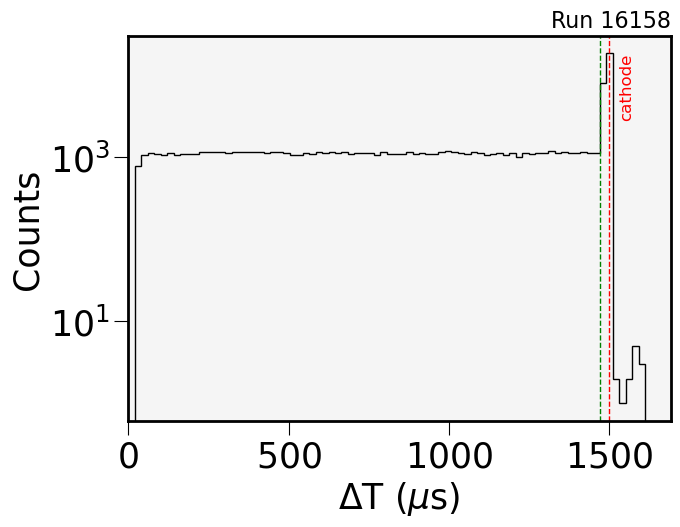

In [14]:
for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Variables
    DT = doro_df['DT']
    # Mask
    mask = EXTRA_INFO[key]['alpha_mask']
    if mask is not None:
        DT = DT[mask]
    print(f"  - DT = [{DT.min():.2f}, {DT.max():.2f}] μs")

    # Negative DT's?
    negative_DT = doro_df[doro_df['DT'] < 0]
    if not negative_DT.empty:
        print(f"  - There are {len(negative_DT)} negative DT values")
    else:
        print(f"  - No negative DT values found")

    # Histogram
    counts, bins, _ = plt.hist(DT, bins=80, range=(0, DT.max()), histtype='step', color='black', lw=1.0)

    # Estimated cathode time position + error
    cath_index   = np.argmax(counts)    # Index of the bin with the highest count
    cath_central = (bins[cath_index] + bins[cath_index + 1]) / 2 
    cath_error   = (bins[1] - bins[0]) / 2
    print(f"  - Cathode position = ({cath_central:.2f} ± {cath_error:.2f}) μs")

    # Plot
    plt.xlabel('$\Delta$T ($\mu$s)')
    plt.ylabel('Counts')
    plt.yscale('log')
    plt.xlim(bins[0], bins[-1]*1.05)
    plt.title(f'Run {key}', loc='right', fontsize=16)
    # Cathode line
    plt.axvline(x=cath_central, c='red', ls='--', lw=1)
    plt.text(1.02*cath_central, counts[cath_index], 'cathode', c='red', va='top',  ha='left',  rotation=90, fontsize=12)
    plt.axvline(x=EXTRA_INFO[key]['cath_lim'], c='green', ls='--', lw=1)

    plt.gca().set_facecolor("whitesmoke")
    # plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/images/DT_dist_run_{key}.pdf')
    plt.show()

## $S1$ Pulse

#### Width


Run 16158:
  - S1 Width = [0.30, 1.25] μs


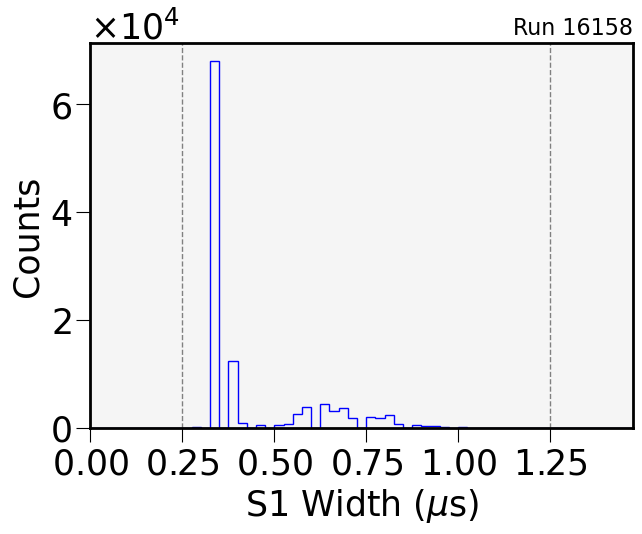

In [15]:
# Params
bins = np.arange(0, 1.5, 0.025)  # In [μs]

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Variables
    W1 = doro_df['S1w'] / 1e3   # [μs]
    print(f"  - S1 Width = [{W1.min():.2f}, {W1.max():.2f}] μs")

    # Histogram
    counts, _, _ = plt.hist(W1, bins=bins, range=None, histtype='step', color='blue', lw=1.0)

    # Plot
    plt.xlabel('S1 Width ($\mu$s)')
    plt.ylabel('Counts')
    # plt.yscale('log')
    plt.xlim(bins[0], bins[-1])
    plt.xticks(bins[::10])
    plt.title(f'Run {key}', loc='right', fontsize=16)
    # Cut line
    plt.axvline(x=0.25, c='gray', ls='--', lw=1)
    plt.axvline(x=1.25, c='gray', ls='--', lw=1)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()

#### Height

Run 16158:
  - S1 Height = [32.19, 495.59] PE


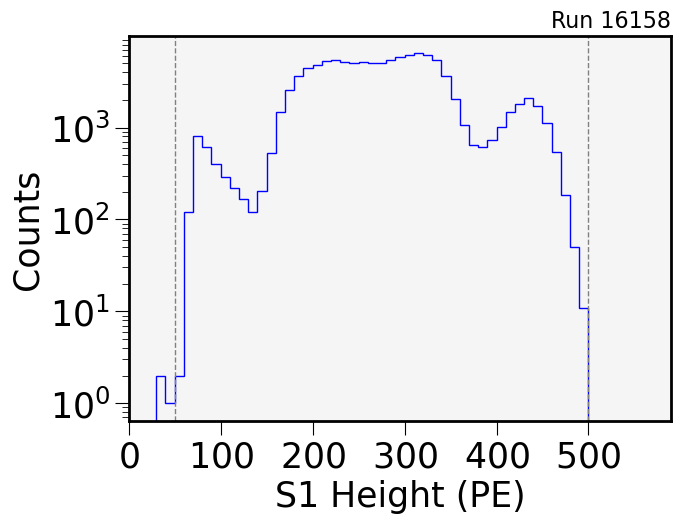

In [ ]:
# Params
bins = np.arange(0, 600, 10)

for key in SEL_DICT.keys():

    print(f"Run {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Variables
    H1 = doro_df['S1h']
    print(f"  - S1 Height = [{H1.min():.2f}, {H1.max():.2f}] PE")
    # print(bins)

    # Histogram
    counts, _, _ = plt.hist(H1, bins=bins, histtype='step', color='blue', lw=1.0)

    # Plot
    plt.xlabel('S1 Height (PE)')
    plt.ylabel('Counts')
    plt.yscale('log')
    plt.xlim(bins[0], bins[-1])
    plt.xticks(bins[::10])
    plt.title(f'Run {key}', loc='right', fontsize=16)
    # Cut line
    plt.axvline(x=50, c='gray', ls='--', lw=1)
    plt.axvline(x=500, c='gray', ls='--', lw=1)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()

## $S2$ Pulse

#### Width


Run 16158:
  - S2 Width = [10.75, 199.25] μs


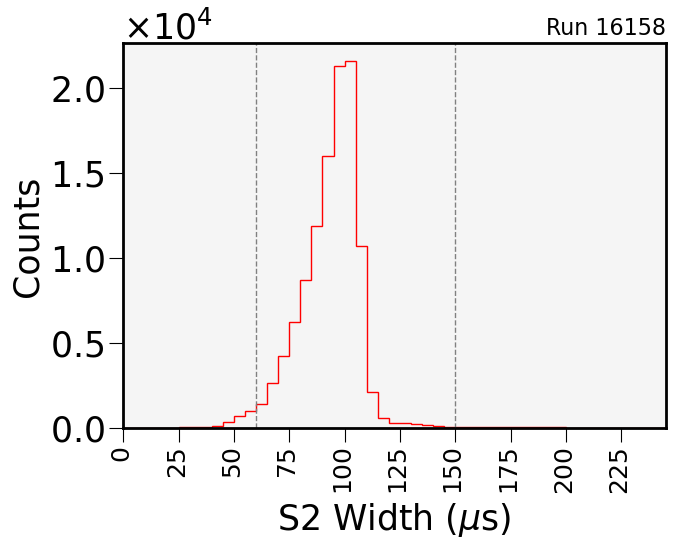

In [20]:
# Params
bins = np.arange(0, 250, 5)  # In [μs]

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Variables
    W2 = doro_df['S2w']
    print(f"  - S2 Width = [{W2.min():.2f}, {W2.max():.2f}] μs")

    # Histogram
    counts, _, _ = plt.hist(W2, bins=bins, histtype='step', color='red', lw=1.0) 

    # Plot
    plt.xlabel('S2 Width ($\mu$s)')
    plt.ylabel('Counts')
    # plt.yscale('log')
    plt.xlim(bins[0], bins[-1])
    plt.xticks(np.arange(bins[0], bins[-1], 25), fontsize=18, rotation='vertical')
    plt.title(f'Run {key}', loc='right', fontsize=16)
    
    # Cut line
    plt.axvline(x=60, c='gray', ls='--', lw=1)
    plt.axvline(x=150, c='gray', ls='--', lw=1)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()

#### Height

Run 16158:
  - S2 Height = [1964.06, 312281.44] μs


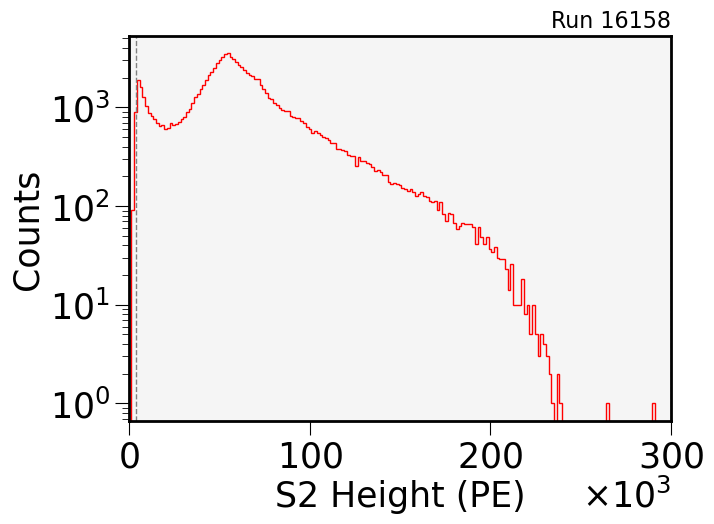

In [27]:
# Params
bins = np.linspace(0, 300e3, 200)  # In [μs]

for key in SEL_DICT.keys():

    print(f"Run {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Variables
    H2 = doro_df['S2h']
    print(f"  - S2 Height = [{H2.min():.2f}, {H2.max():.2f}] μs")
    # print(H2.describe())

    # Histogram
    counts, _, _ = plt.hist(H2, bins=bins, range=None, histtype='step', color='red', lw=1.0)

    # Plot
    plt.xlabel('S2 Height (PE)')
    plt.ylabel('Counts')
    plt.yscale('log')
    plt.xlim(bins[0], bins[-1]) 
    plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
    plt.title(f'Run {key}', loc='right', fontsize=16)

    # Cut line
    plt.axvline(x=4e3, c='gray', ls='--', lw=1)
    plt.axvline(x=300e3, c='gray', ls='--', lw=1)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()

# Maps

### $S1$ Pulse

#### Width

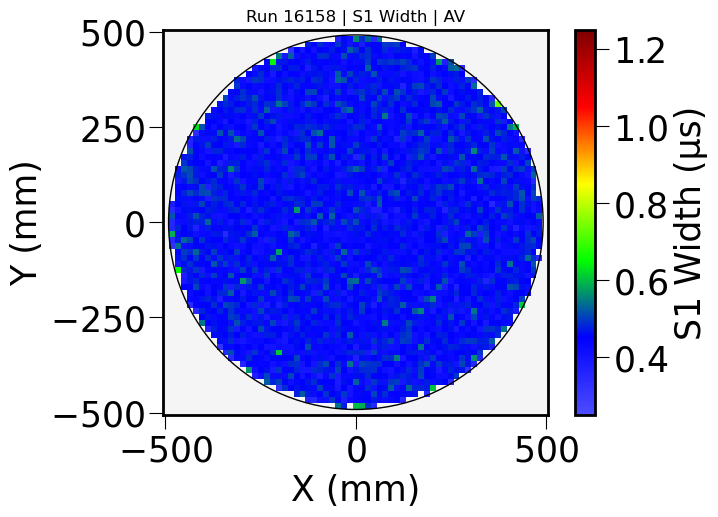

In [28]:
# Params
w1_min = 0.25
w1_max = 1.25

for key in SEL_DICT.keys():
    
    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask'])
    if mask is not None:
        doro_df = doro_df[mask].copy()

    # Variables    
    X = doro_df['X']
    Y = doro_df['Y']
    W1 = doro_df['S1w'] / 1e3

    # Map
    s1w_map, ex, ey = crudo.pt.mapping(X, Y, wei=W1, bin_scale=1, max_limit=crudo.pt.N100_rad, norm=False)
    s1w_map         = np.ma.masked_where(s1w_map==0, s1w_map)

    # Plot
    plt.pcolormesh(ex, ey, s1w_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=w1_min, vmax=w1_max)
    plt.colorbar(label='S1 Width (μs)')
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | S1 Width | AV', loc='center', fontsize=12)  

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()

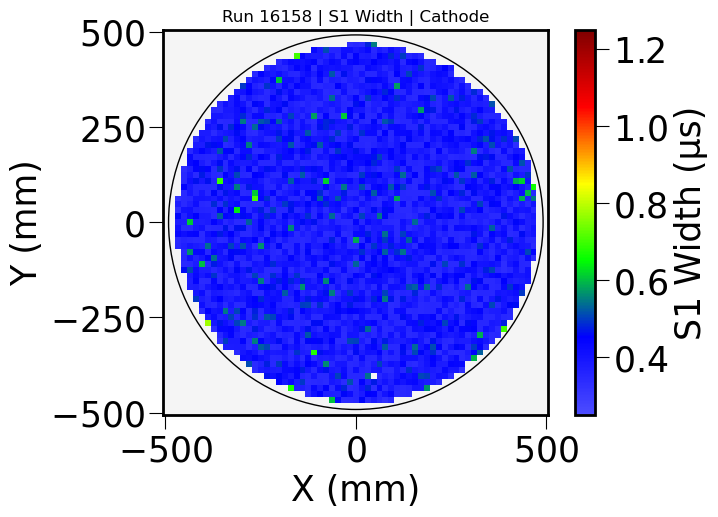

In [29]:
# Params
w1_min = 0.25
w1_max = 1.25

for key in SEL_DICT.keys():
    
    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['cath_mask'])
    if mask is not None:
        doro_df = doro_df[mask].copy()

    # Variables    
    X = doro_df['X']
    Y = doro_df['Y']
    W1 = doro_df['S1w'] / 1e3

    # Map
    s1w_map, ex, ey = crudo.pt.mapping(X, Y, wei=W1, bin_scale=1, max_limit=crudo.pt.N100_rad, norm=False)
    s1w_map         = np.ma.masked_where(s1w_map==0, s1w_map)

    # Plot
    plt.pcolormesh(ex, ey, s1w_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=w1_min, vmax=w1_max)
    plt.colorbar(label='S1 Width (μs)')
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | S1 Width | Cathode', loc='center', fontsize=12)  

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()

#### Height

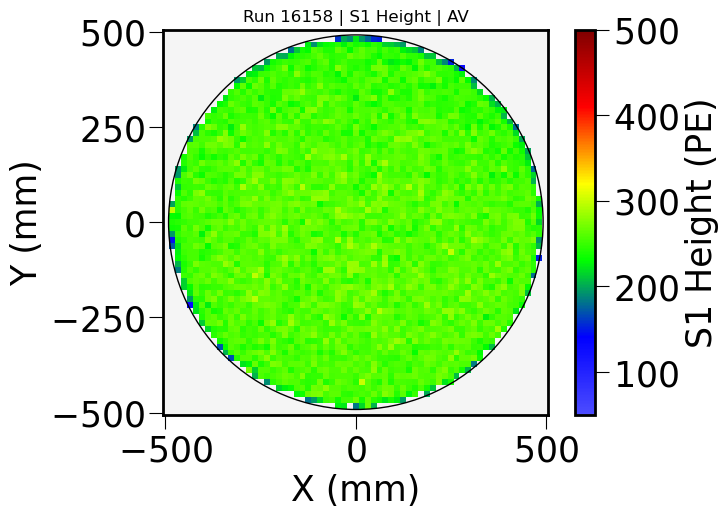

In [30]:
# Params
h1_min = 50
h1_max = 500

for key in SEL_DICT.keys():
    
    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask'])
    if mask is not None:
        doro_df = doro_df[mask].copy()

    # Variables    
    X = doro_df['X']
    Y = doro_df['Y']
    H1 = doro_df['S1h']

    # Map
    s1h_map, ex, ey = crudo.pt.mapping(X, Y, wei=H1, bin_scale=1, max_limit=crudo.pt.N100_rad, norm=False)
    s1h_map         = np.ma.masked_where(s1h_map==0, s1h_map)

    # Plot
    plt.pcolormesh(ex, ey, s1h_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=h1_min, vmax=h1_max)
    plt.colorbar(label='S1 Height (PE)')
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | S1 Height | AV', loc='center', fontsize=12)  

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()

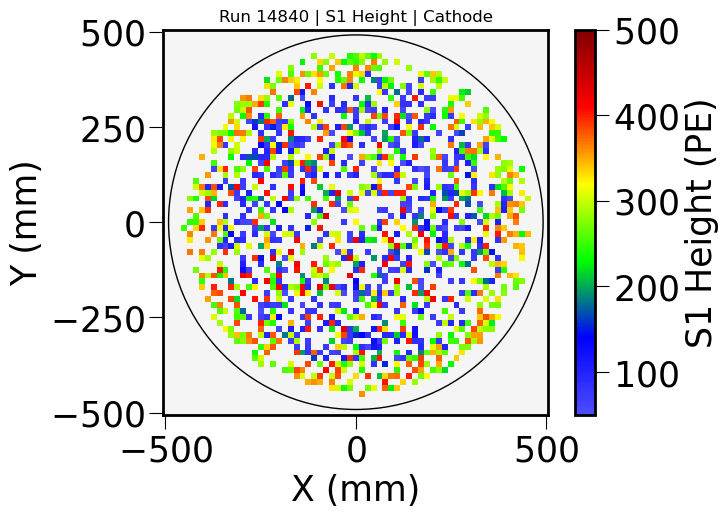

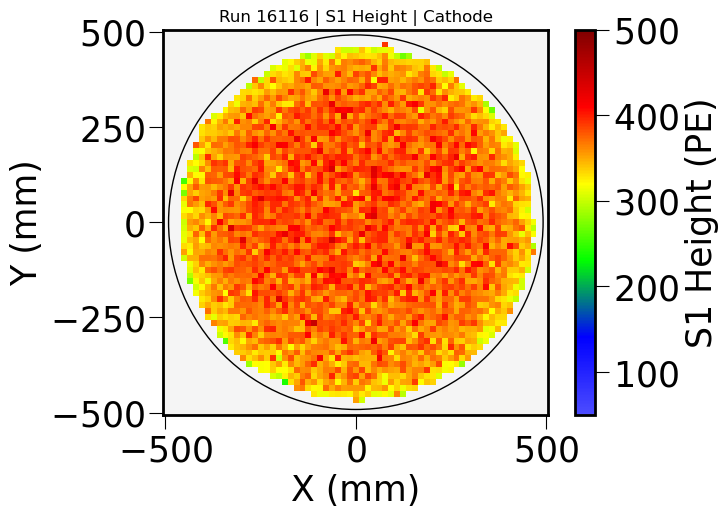

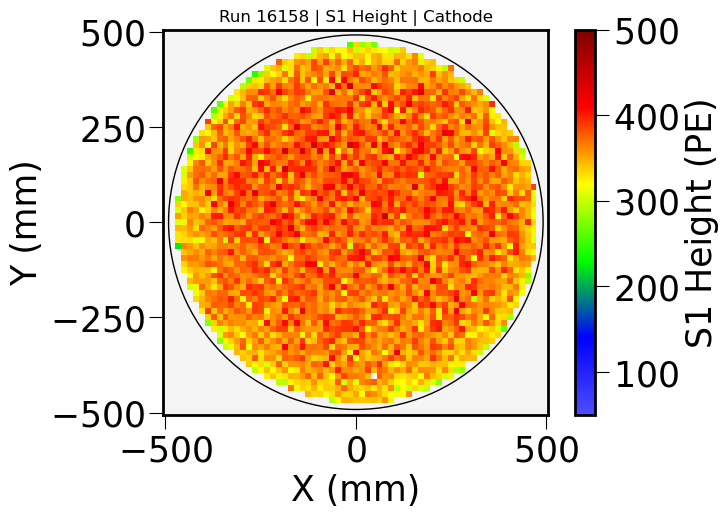

In [64]:
# Params
h1_min = 50
h1_max = 500

for key in SEL_DICT.keys():
    
    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['cath_mask'])
    if mask is not None:
        doro_df = doro_df[mask].copy()

    # Variables    
    X = doro_df['X']
    Y = doro_df['Y']
    H1 = doro_df['S1h']

    # Map
    s1h_map, ex, ey = crudo.pt.mapping(X, Y, wei=H1, bin_scale=1, max_limit=crudo.pt.N100_rad, norm=False)
    s1h_map         = np.ma.masked_where(s1h_map==0, s1h_map)

    # Plot
    plt.pcolormesh(ex, ey, s1h_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=h1_min, vmax=h1_max)
    plt.colorbar(label='S1 Height (PE)')
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | S1 Height | Cathode', loc='center', fontsize=12)  

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()

### $S2$ Pulse

#### Width

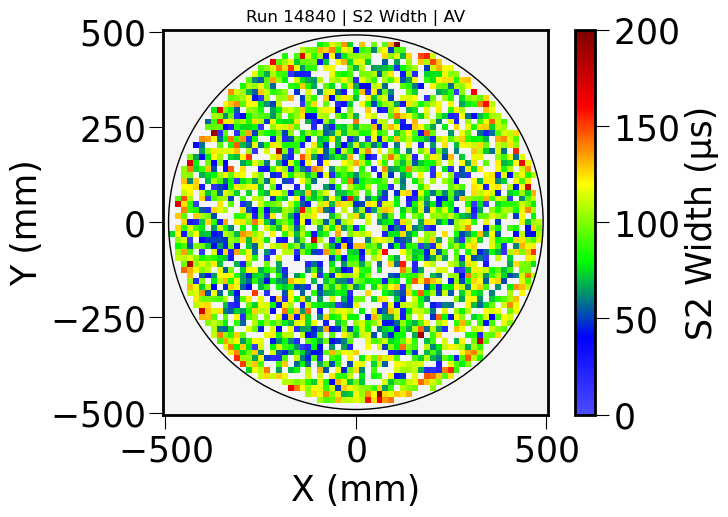

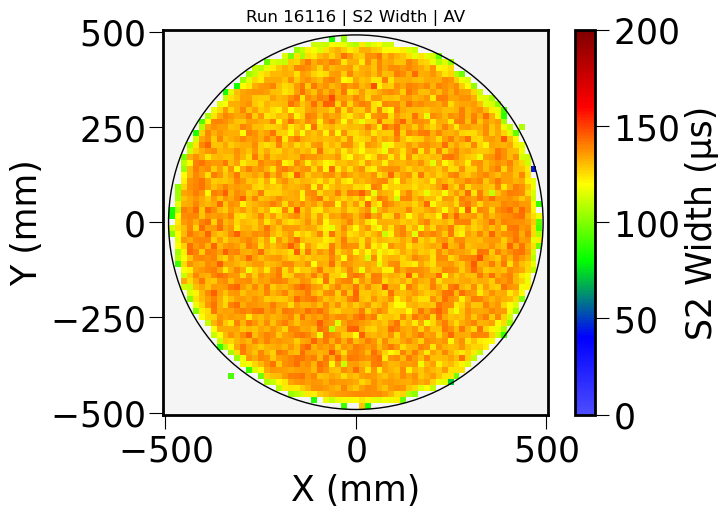

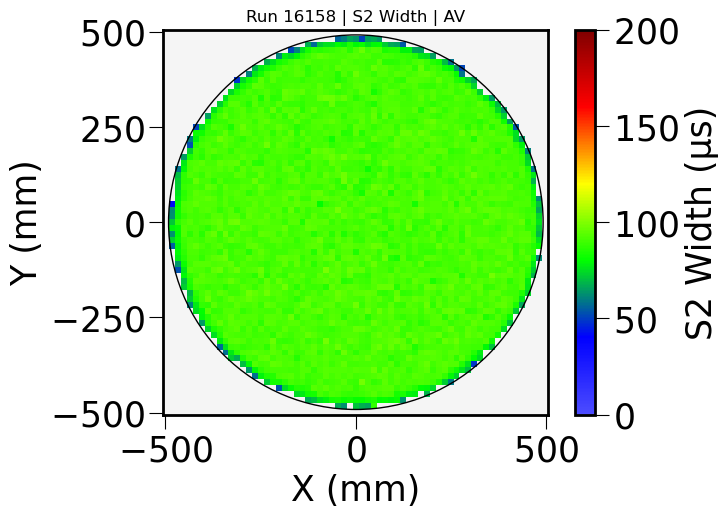

In [74]:
# Params
w2_min = 0
w2_max = 200

for key in SEL_DICT.keys():

    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask'])
    if mask is not None:
        doro_df = doro_df[mask].copy()

    # Variables    
    X = doro_df['X']
    Y = doro_df['Y']
    W2 = doro_df['S2w']

    # Map
    s2w_map, ex, ey = crudo.pt.mapping(X, Y, wei=W2, bin_scale=1, max_limit=crudo.pt.N100_rad, norm=False)
    s2w_map         = np.ma.masked_where(s2w_map==0, s2w_map)

    # Plot
    plt.pcolormesh(ex, ey, s2w_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=w2_min, vmax=w2_max)
    plt.colorbar(label='S2 Width (μs)')
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | S2 Width | AV', loc='center', fontsize=12) 

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()

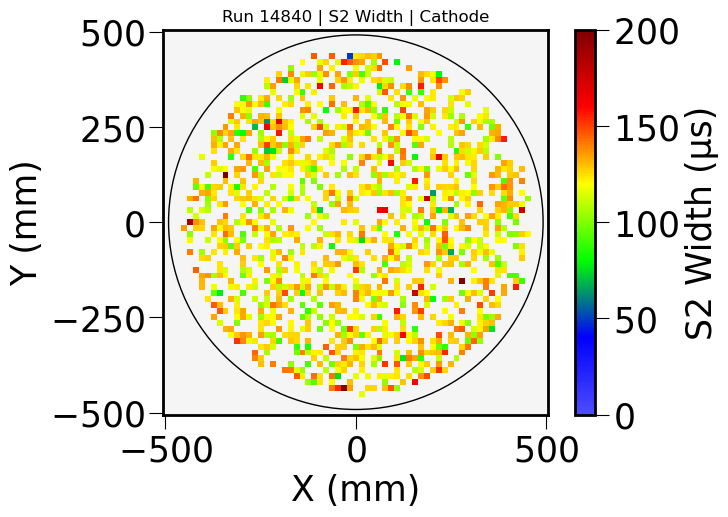

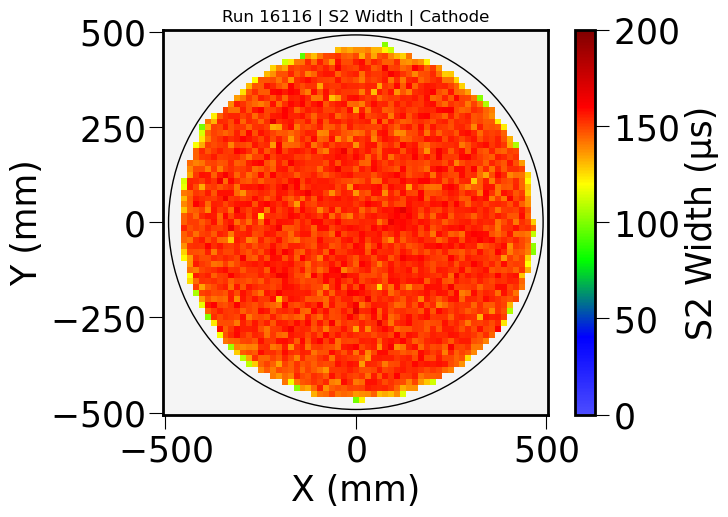

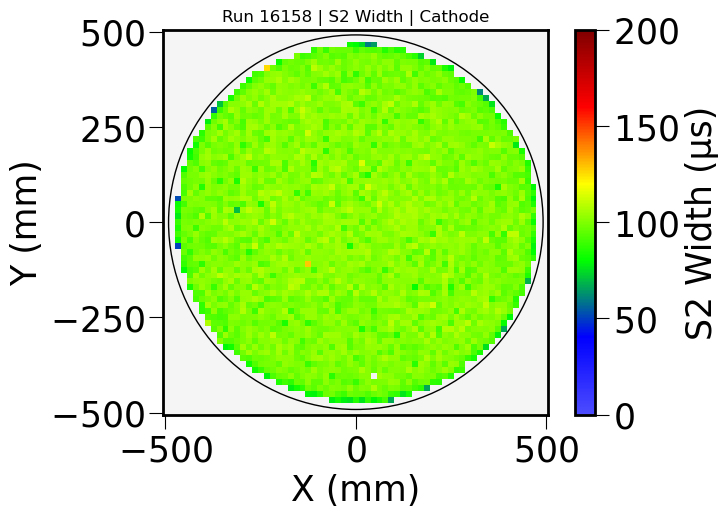

In [75]:
# Params
w2_min = 0
w2_max = 200

for key in SEL_DICT.keys():

    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['cath_mask'])
    if mask is not None:
        doro_df = doro_df[mask].copy()

    # Variables    
    X = doro_df['X']
    Y = doro_df['Y']
    W2 = doro_df['S2w']

    # Map
    s2w_map, ex, ey = crudo.pt.mapping(X, Y, wei=W2, bin_scale=1, max_limit=crudo.pt.N100_rad, norm=False)
    s2w_map         = np.ma.masked_where(s2w_map==0, s2w_map)

    # Plot
    plt.pcolormesh(ex, ey, s2w_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=w2_min, vmax=w2_max)
    plt.colorbar(label='S2 Width (μs)')
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | S2 Width | Cathode', loc='center', fontsize=12) 

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()

#### Height

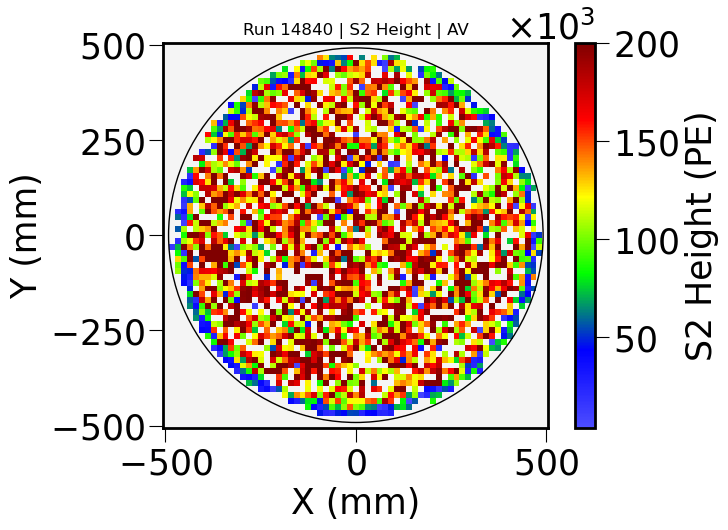

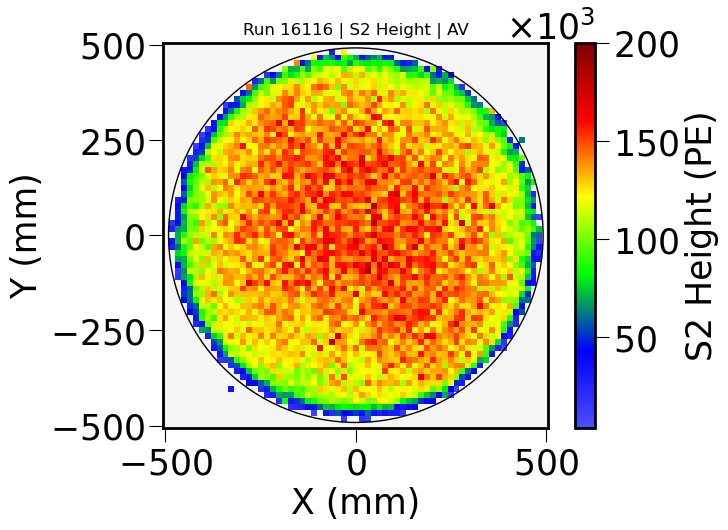

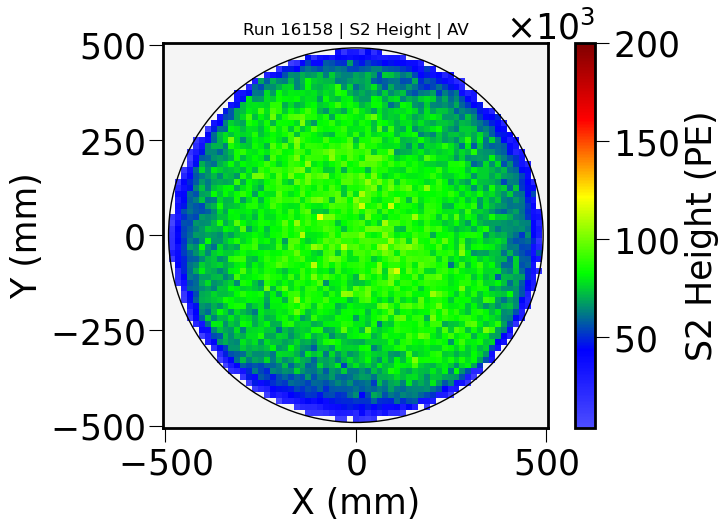

In [80]:
# Params
h2_min = 4e3
h2_max = 200e3

for key in SEL_DICT.keys():

    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask'])
    if mask is not None:
        doro_df = doro_df[mask].copy()

    # Variables    
    X = doro_df['X']
    Y = doro_df['Y']
    H2 = doro_df['S2h']

    # Map
    s2h_map, ex, ey = crudo.pt.mapping(X, Y, wei=H2, bin_scale=1, max_limit=crudo.pt.N100_rad, norm=False)
    s2h_map         = np.ma.masked_where(s2h_map==0, s2h_map)

    # Plot
    plt.pcolormesh(ex, ey, s2h_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=h2_min, vmax=h2_max)
    plt.colorbar(label='S2 Height (PE)').ax.ticklabel_format(axis='y', style='sci', scilimits=(3, 3))
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | S2 Height | AV', loc='center', fontsize=12) 

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()

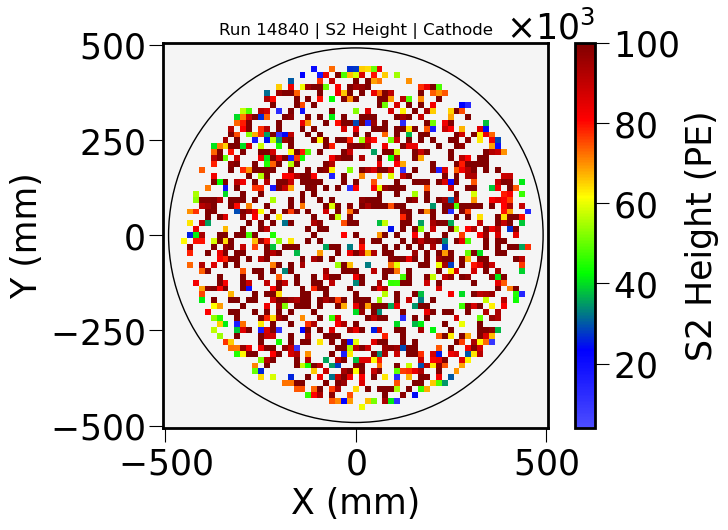

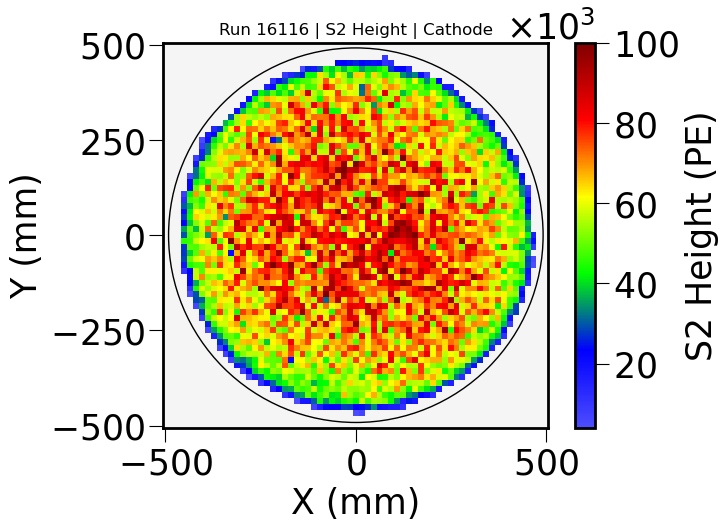

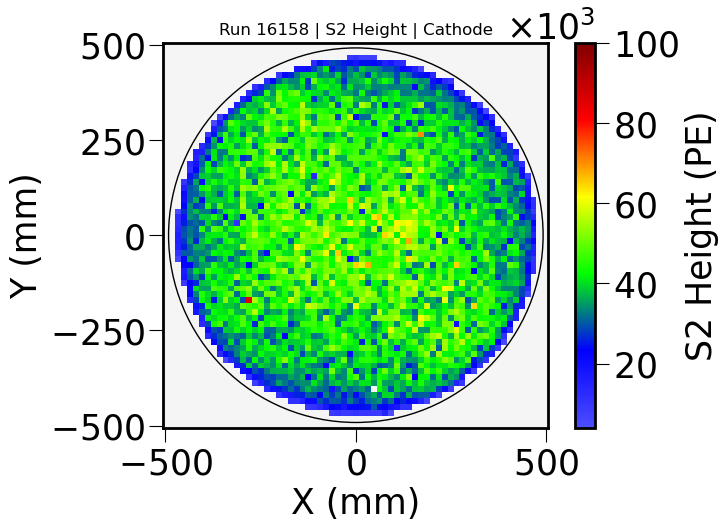

In [82]:
# Params
h2_min = 4e3
h2_max = 100e3

for key in SEL_DICT.keys():

    doro_df = SEL_DICT[key]['doro_df']

    # Masking    
    mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['cath_mask'])
    if mask is not None:
        doro_df = doro_df[mask].copy()

    # Variables    
    X = doro_df['X']
    Y = doro_df['Y']
    H2 = doro_df['S2h']

    # Map
    s2h_map, ex, ey = crudo.pt.mapping(X, Y, wei=H2, bin_scale=1, max_limit=crudo.pt.N100_rad, norm=False)
    s2h_map         = np.ma.masked_where(s2h_map==0, s2h_map)

    # Plot
    plt.pcolormesh(ex, ey, s2h_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=h2_min, vmax=h2_max)
    plt.colorbar(label='S2 Height (PE)').ax.ticklabel_format(axis='y', style='sci', scilimits=(3, 3))
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | S2 Height | Cathode', loc='center', fontsize=12) 

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()

# 2D Histograms

### $S1w$ vs $S1h$


Run 14840:


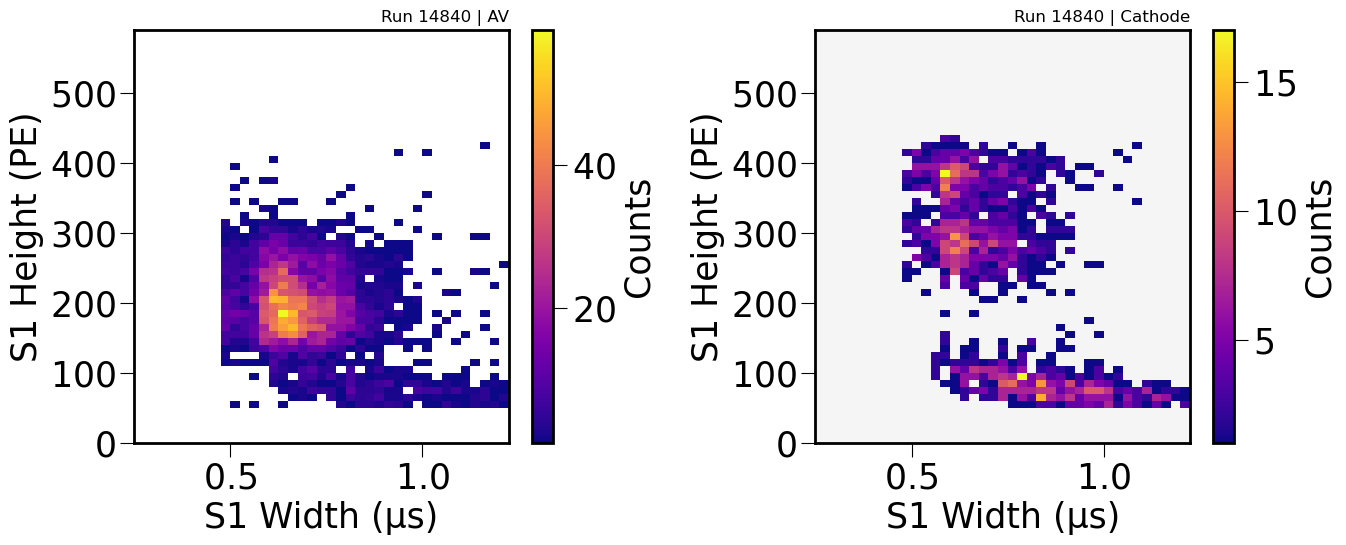


Run 16116:


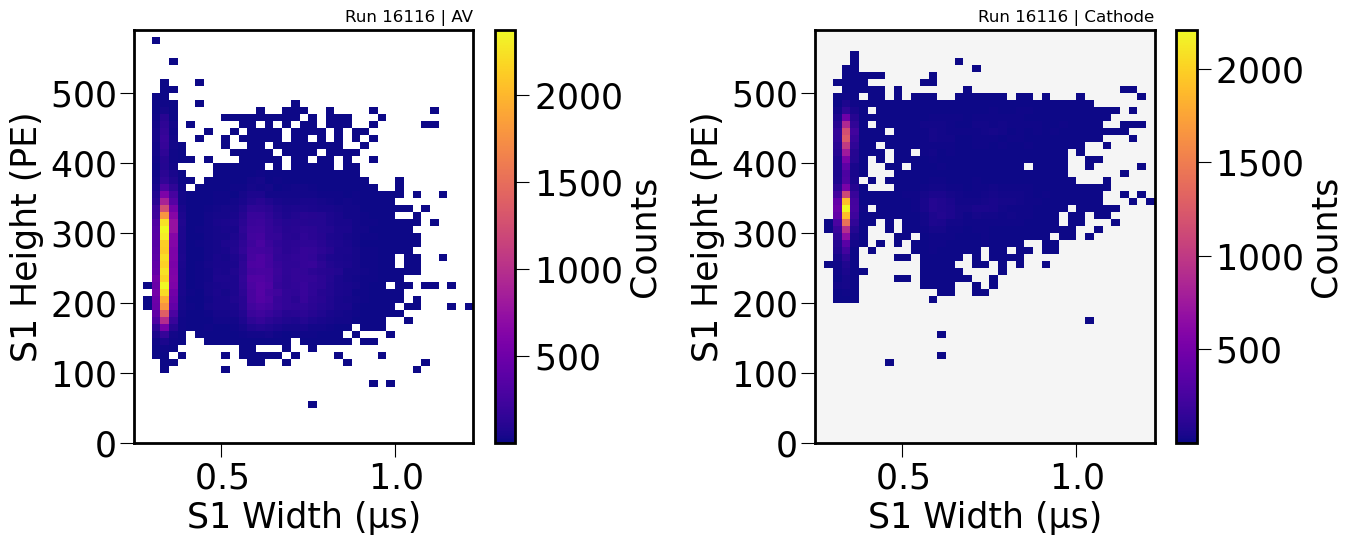


Run 16158:


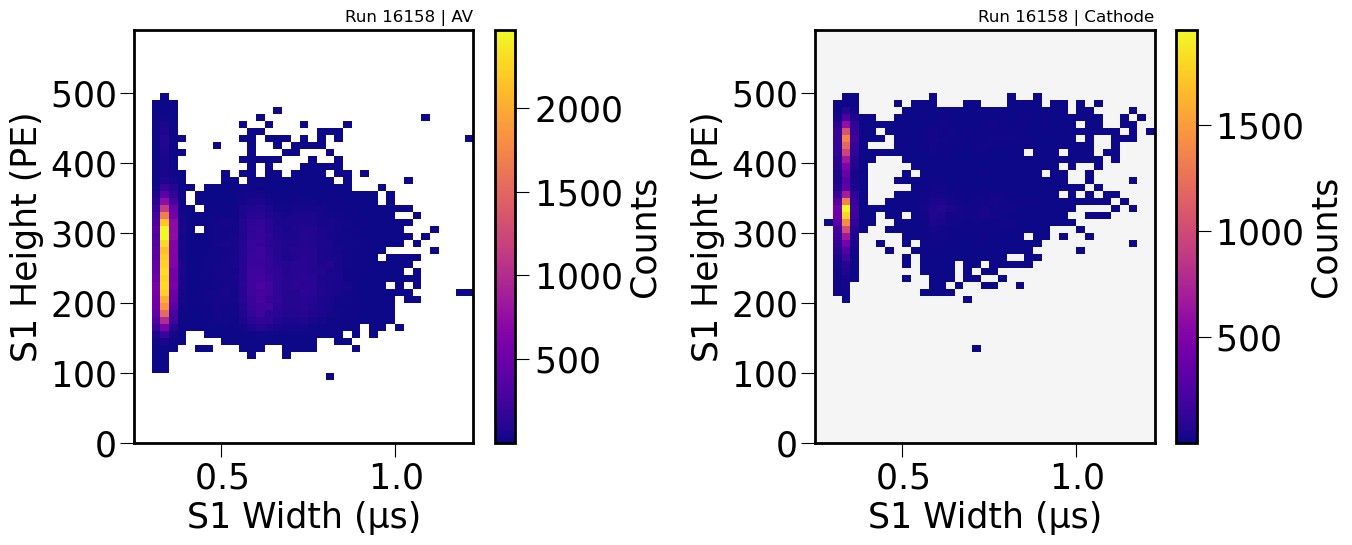

In [ ]:
for key in SEL_DICT.keys():

    doro_df = SEL_DICT[key]['doro_df']

    fig = plt.figure(figsize=(14, 6))
    gs = GridSpec(1, 2, figure=fig)
    ax_left  = fig.add_subplot(gs[0, 0])
    ax_right = fig.add_subplot(gs[0, 1])

    for i, label in enumerate(['AV', 'Cathode']):

        if label == 'AV':
            mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask'])
            ax = ax_left
        else:
            mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['cath_mask'])
            ax = ax_right

        mask_df = doro_df[mask].copy()

        # Variables    
        W1 = mask_df['S1w'] / 1e3
        H1 = mask_df['S1h']

        # 2D Histogram
        s1w_s1h_map, ex, ey = np.histogram2d(W1, H1, bins=[np.arange(0.25, 1.25, 0.025), np.arange(0, 600, 10)])
        s1w_s1h_map         = np.ma.masked_where(s1w_s1h_map==0, s1w_s1h_map)

        # Plot
        pcm = ax.pcolormesh(ex, ey, s1w_s1h_map.T, cmap='plasma', shading='auto')
        plt.colorbar(pcm, ax=ax, label='Counts')
        ax.set_xlabel('S1 Width (μs)')
        ax.set_ylabel('S1 Height (PE)')
        ax.set_yticks(ey[::10])
        ax.set_title(f'Run {key} | {label}', loc='right', fontsize=12)

    plt.gca().set_facecolor("whitesmoke")
    plt.tight_layout()
    plt.show()

### $S1w$ vs DT

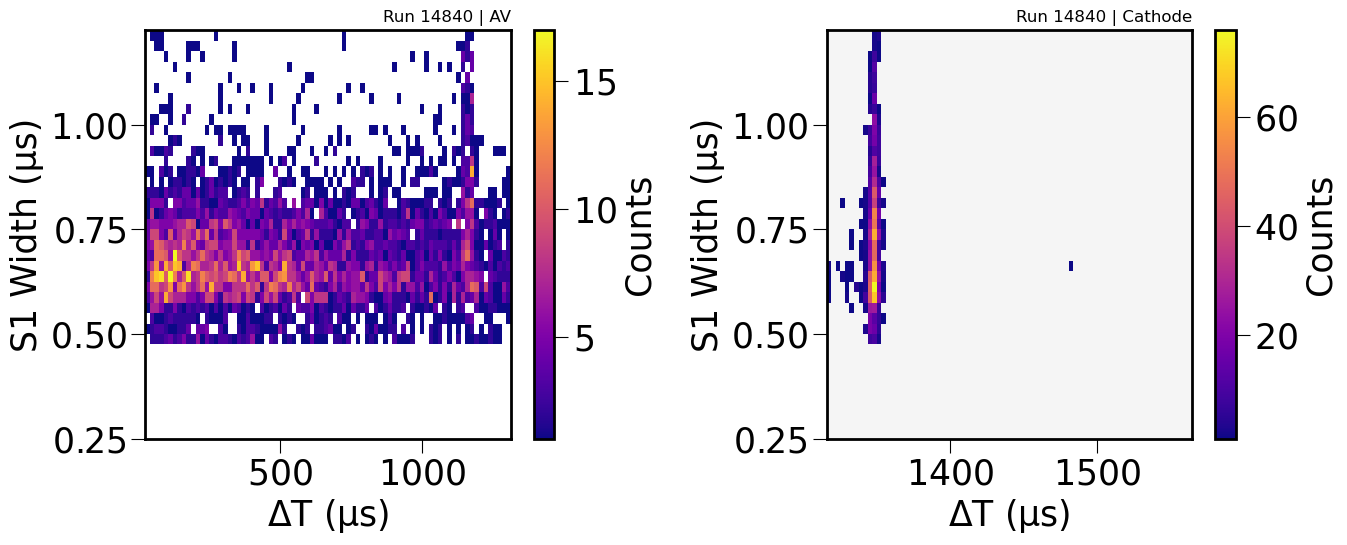

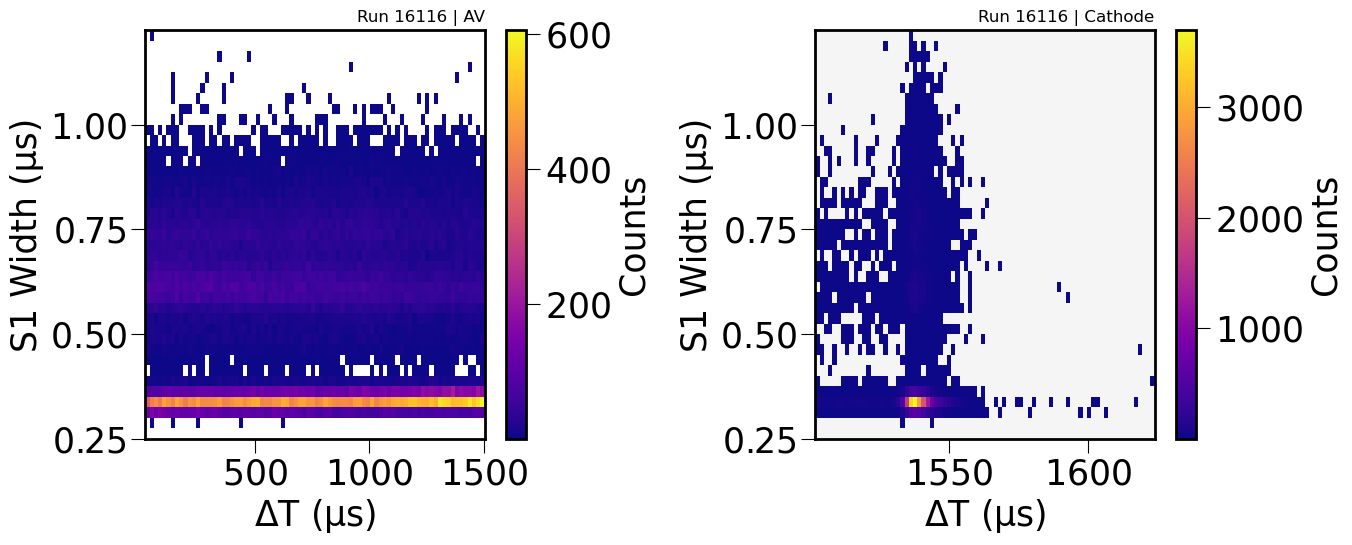

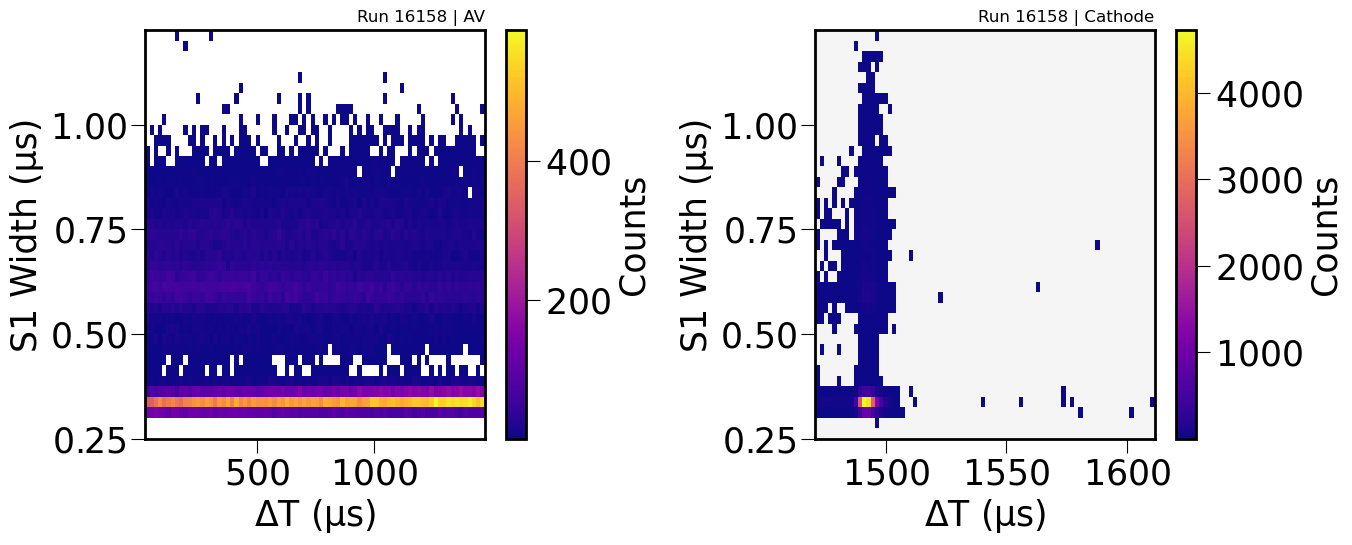

In [121]:
for key in SEL_DICT.keys():

    doro_df = SEL_DICT[key]['doro_df']

    fig = plt.figure(figsize=(14, 6))
    gs = GridSpec(1, 2, figure=fig)
    ax_left  = fig.add_subplot(gs[0, 0])
    ax_right = fig.add_subplot(gs[0, 1])

    for i, label in enumerate(['AV', 'Cathode']):

        if label == 'AV':
            mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask'])
            ax = ax_left
        else:
            mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['cath_mask'])
            ax = ax_right

        mask_df = doro_df[mask].copy()

        # Variables    
        DT = mask_df['DT']
        W1 = mask_df['S1w'] / 1e3

        # 2D Histogram
        s1w_s1h_map, ex, ey = np.histogram2d(DT, W1, bins=[80, np.arange(0.25, 1.25, 0.025)])
        s1w_s1h_map         = np.ma.masked_where(s1w_s1h_map==0, s1w_s1h_map)

        # Plot
        pcm = ax.pcolormesh(ex, ey, s1w_s1h_map.T, cmap='plasma', shading='auto')
        plt.colorbar(pcm, ax=ax, label='Counts')
        ax.set_xlabel('$\Delta$T (μs)')
        ax.set_ylabel('S1 Width (μs)')
        ax.set_yticks(ey[::10])
        ax.set_title(f'Run {key} | {label}', loc='right', fontsize=12)

    plt.gca().set_facecolor("whitesmoke")
    plt.tight_layout()
    plt.show()

### $S1h$ vs DT

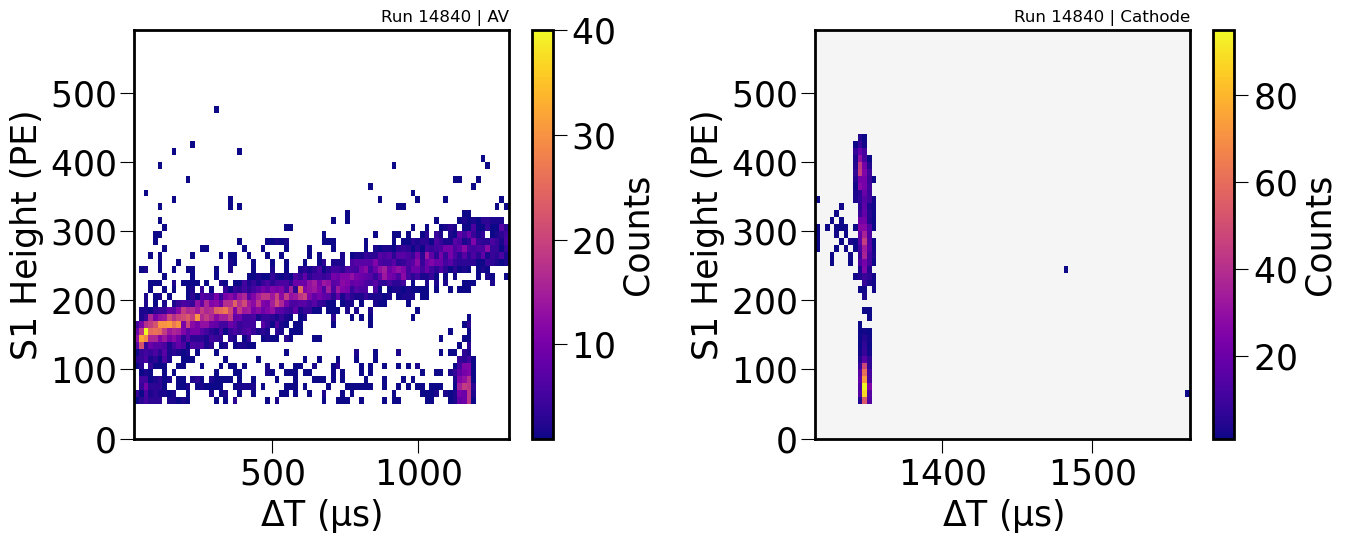

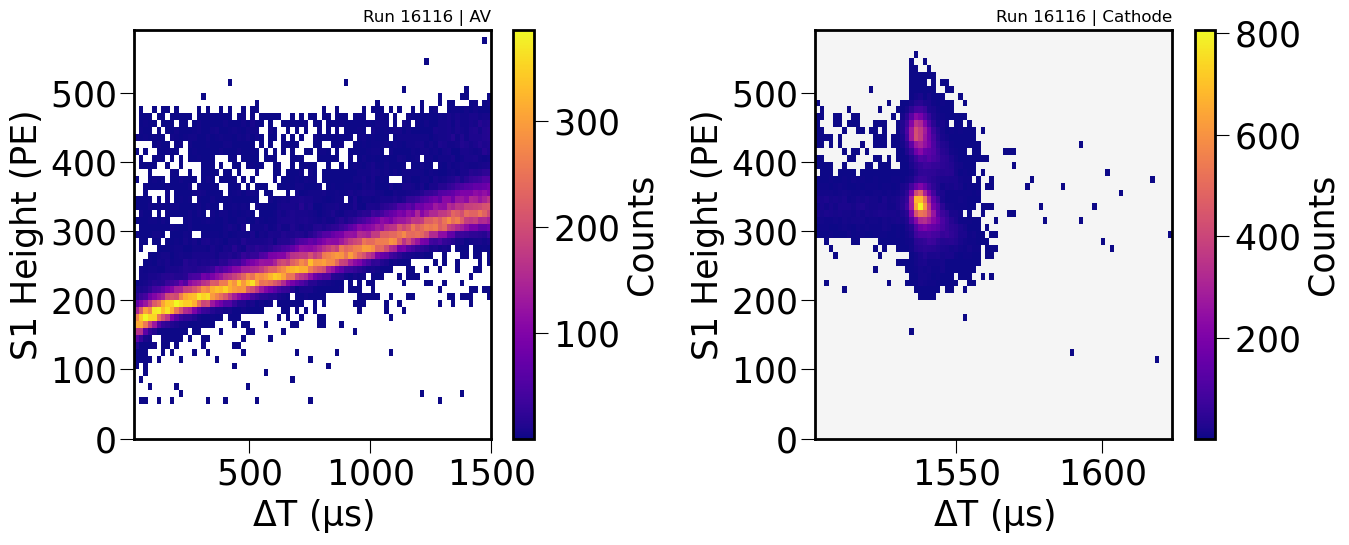

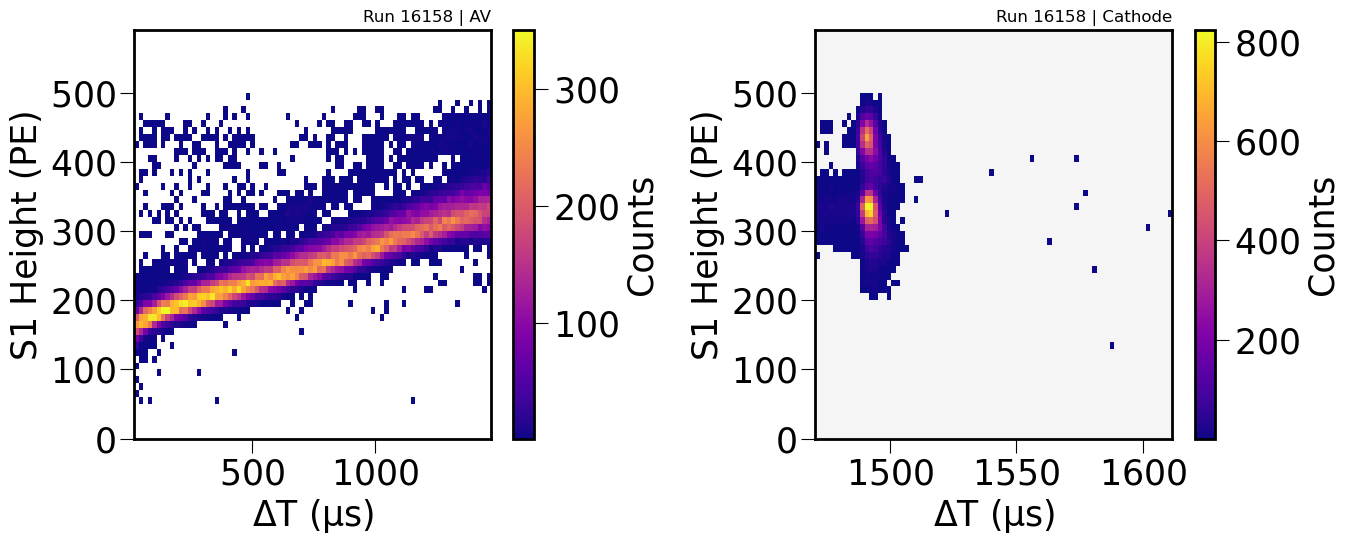

In [117]:
for key in SEL_DICT.keys():

    doro_df = SEL_DICT[key]['doro_df']

    fig = plt.figure(figsize=(14, 6))
    gs = GridSpec(1, 2, figure=fig)
    ax_left  = fig.add_subplot(gs[0, 0])
    ax_right = fig.add_subplot(gs[0, 1])

    for i, label in enumerate(['AV', 'Cathode']):

        if label == 'AV':
            mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask'])
            ax = ax_left
        else:
            mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['cath_mask'])
            ax = ax_right

        mask_df = doro_df[mask].copy()

        # Variables    
        DT = mask_df['DT']
        H1 = mask_df['S1h']

        # 2D Histogram
        s1w_s1h_map, ex, ey = np.histogram2d(DT, H1, bins=[80, np.arange(0, 600, 10)])
        s1w_s1h_map         = np.ma.masked_where(s1w_s1h_map==0, s1w_s1h_map)

        # Plot
        pcm = ax.pcolormesh(ex, ey, s1w_s1h_map.T, cmap='plasma', shading='auto')
        plt.colorbar(pcm, ax=ax, label='Counts')
        ax.set_xlabel('$\Delta$T (μs)')
        ax.set_ylabel('S1 Height (PE)')
        ax.set_yticks(ey[::10])
        ax.set_title(f'Run {key} | {label}', loc='right', fontsize=12)

    plt.gca().set_facecolor("whitesmoke")
    plt.tight_layout()
    plt.show()

### $S2w$ vs $S2h$

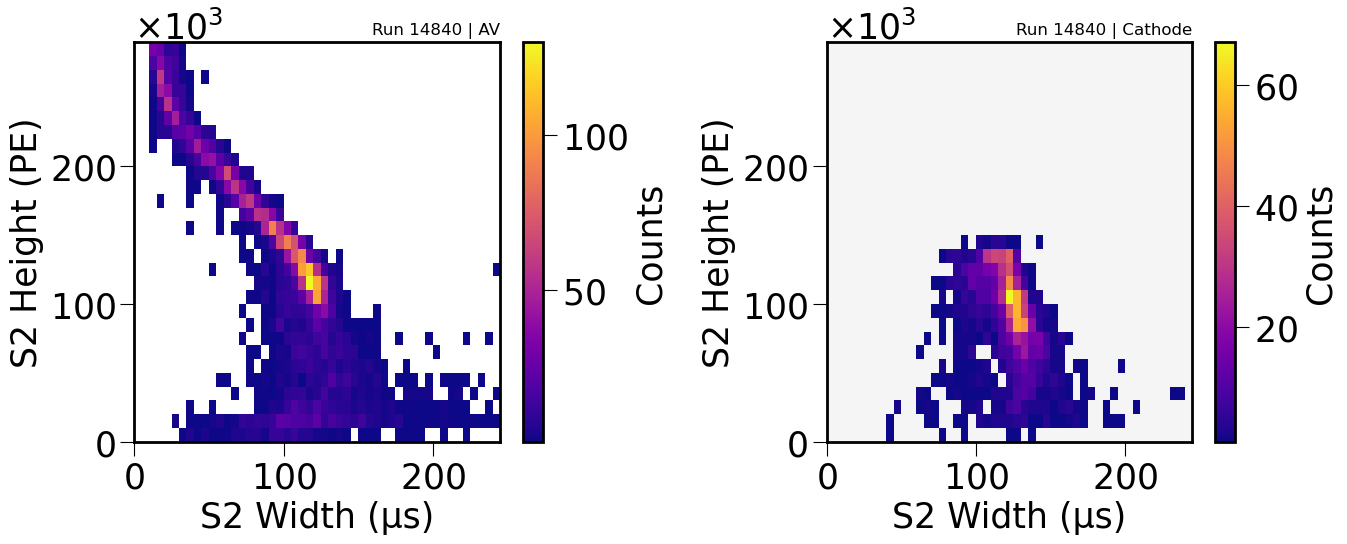

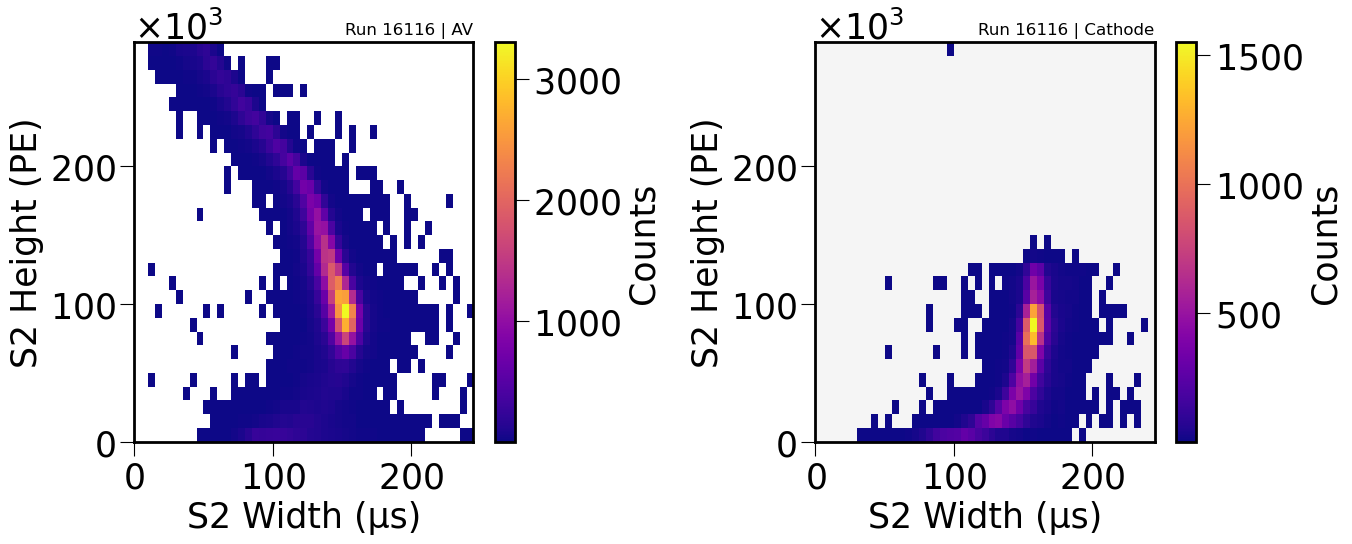

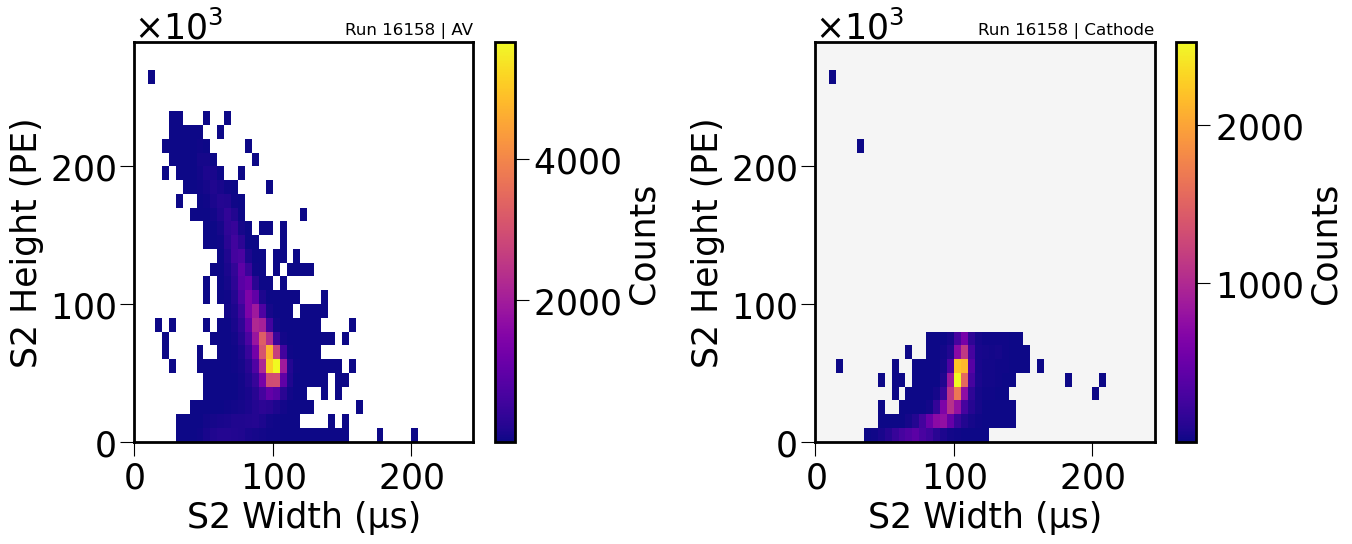

In [ ]:
for key in SEL_DICT.keys():

    doro_df = SEL_DICT[key]['doro_df']

    fig = plt.figure(figsize=(14, 6))
    gs = GridSpec(1, 2, figure=fig)
    ax_left  = fig.add_subplot(gs[0, 0])
    ax_right = fig.add_subplot(gs[0, 1])

    for i, label in enumerate(['AV', 'Cathode']):

        if label == 'AV':
            mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask'])
            ax = ax_left
        else:
            mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['cath_mask'])
            ax = ax_right

        mask_df = doro_df[mask].copy()

        # Variables    
        W2 = mask_df['S2w']
        H2 = mask_df['S2h']

        # 2D Histogram
        s1w_s1h_map, ex, ey = np.histogram2d(W2, H2, bins=[np.arange(0, 250, 5), np.arange(0, 300e3, 10e3)])
        s1w_s1h_map         = np.ma.masked_where(s1w_s1h_map==0, s1w_s1h_map)

        # Plot
        pcm = ax.pcolormesh(ex, ey, s1w_s1h_map.T, cmap='plasma', shading='auto')
        plt.colorbar(pcm, ax=ax, label='Counts')
        ax.set_xlabel('S2 Width (μs)')
        ax.set_ylabel('S2 Height (PE)')
        ax.ticklabel_format(axis='y', style='sci', scilimits=(3, 3))
        ax.set_yticks(ey[::10])
        ax.set_title(f'Run {key} | {label}', loc='right', fontsize=12)

    plt.gca().set_facecolor("whitesmoke")
    plt.tight_layout()
    plt.show()

### $S2w$ vs DT

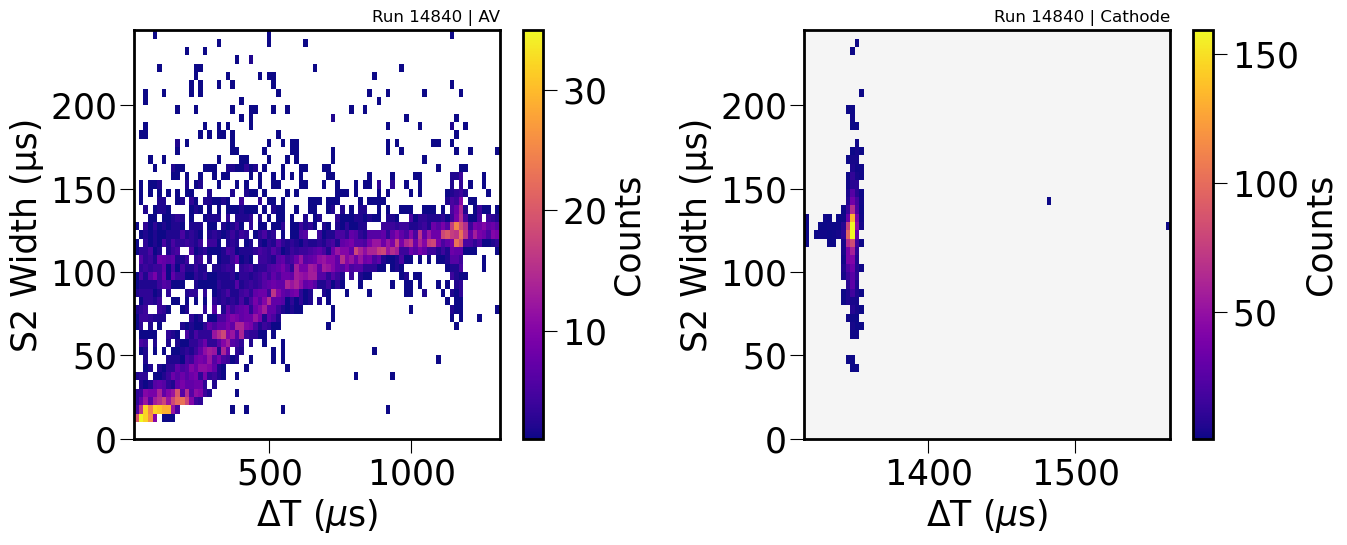

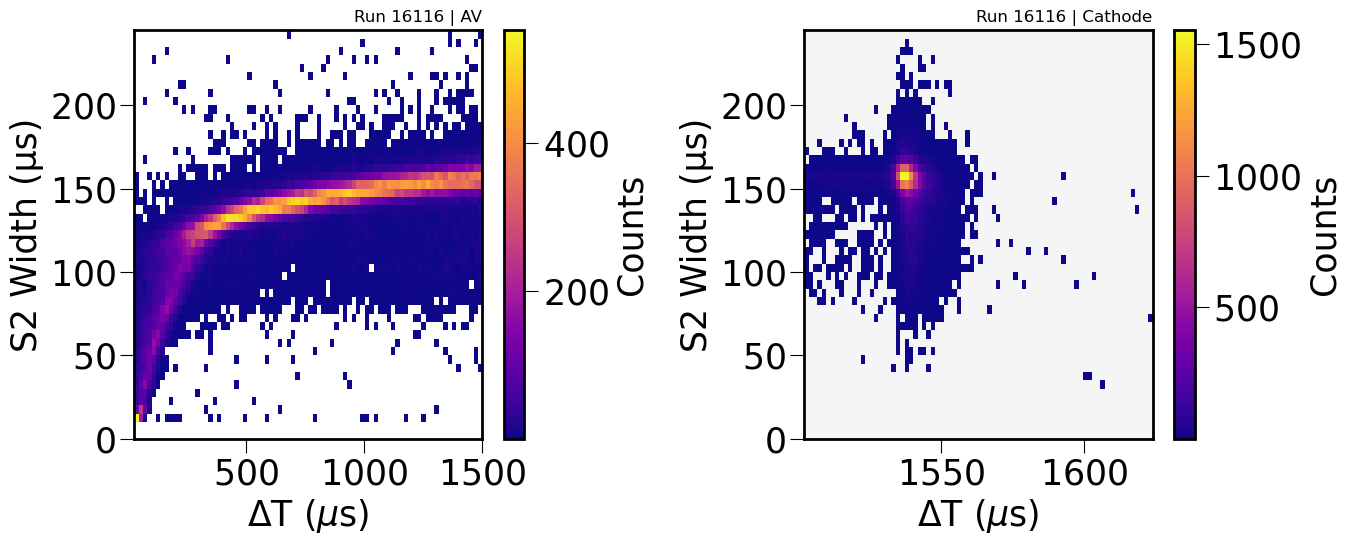

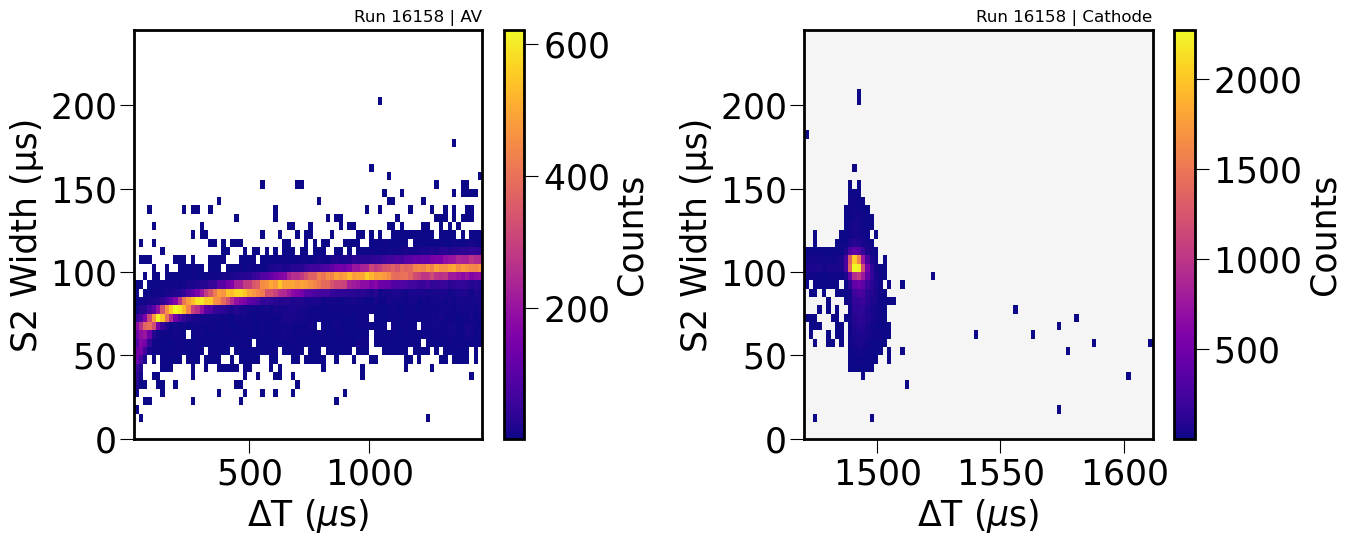

In [128]:
for key in SEL_DICT.keys():

    doro_df = SEL_DICT[key]['doro_df']

    fig = plt.figure(figsize=(14, 6))
    gs = GridSpec(1, 2, figure=fig)
    ax_left  = fig.add_subplot(gs[0, 0])
    ax_right = fig.add_subplot(gs[0, 1])

    for i, label in enumerate(['AV', 'Cathode']):

        if label == 'AV':
            mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask'])
            ax = ax_left
        else:
            mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['cath_mask'])
            ax = ax_right

        mask_df = doro_df[mask].copy()

        # Variables    
        W2 = mask_df['S2w']
        DT = mask_df['DT']

        # 2D Histogram
        s2w_dt_map, ex, ey = np.histogram2d(DT, W2, bins=[80, np.arange(0, 250, 5)])
        s2w_dt_map         = np.ma.masked_where(s2w_dt_map==0, s2w_dt_map)

        # Plot
        pcm = ax.pcolormesh(ex, ey, s2w_dt_map.T, cmap='plasma', shading='auto')
        plt.colorbar(pcm, ax=ax, label='Counts')
        ax.set_xlabel('$\Delta$T ($\mu$s)')
        ax.set_ylabel('S2 Width (μs)')
        ax.set_yticks(ey[::10])
        ax.set_title(f'Run {key} | {label}', loc='right', fontsize=12)

    plt.gca().set_facecolor("whitesmoke")
    plt.tight_layout()
    plt.show()

In [129]:
# rad_max = 500
# rad_min = 0

# for key in SEL_DICT.keys():
    
#     doro_df = SEL_DICT[key]['doro_df']
#     gate_voltage = RUNS_INFO_DF[RUNS_INFO_DF['run_number'] == int(key.split('_')[0])]['gate_voltage'].values[0] / 1e3

#     # Variables    
#     W2 = doro_df['S2w']
#     DT = doro_df['DT']
#     R = np.sqrt(doro_df['X']**2 + doro_df['Y']**2)

#     # Masking
#     mask = (EXTRA_INFO[key]['AV_Z_mask']) & (EXTRA_INFO[key]['alpha_mask']) & (R >= rad_min) & (R <= rad_max)
#     # mask = (R <= 200)
#     # mask = None
#     if mask is not None:
#         W2 = W2[mask]
#         DT = DT[mask]

#     # 2D Histogram
#     s2w_dt_map, ex, ey = np.histogram2d(DT, W2, bins=[50, 75])
#     s2w_dt_map         = np.ma.masked_where(s2w_dt_map==0, s2w_dt_map)

#     # Plot
#     plt.pcolormesh(ex, ey, s2w_dt_map.T, cmap='plasma', shading='auto')
#     plt.colorbar(label='Counts')
#     plt.xlabel('$\Delta$T ($\mu$s)')
#     plt.ylabel('S2 Width ($\mu$s)')
#     plt.xlim(ex[0], ex[-1])
#     plt.ylim(0, 200)
#     plt.xticks(np.arange(0, DT.max(), 300))
#     # plt.ticklabel_format(axis='y', style='sci', scilimits=(3, 3))
#     plt.title (f'Run {key} | AV + (R = [{rad_min}, {rad_max}] mm) | Gate = {gate_voltage:.1f} kV', loc='right', fontsize=10)

#     # Lines
#     # plt.axvline(x=150, c='gray', ls='--', lw=2)
#     # plt.axhline(y=25, c='gray', ls='--', lw=2)

#     plt.gca().set_facecolor("whitesmoke")
#     plt.show()

### $S2h$ vs DT

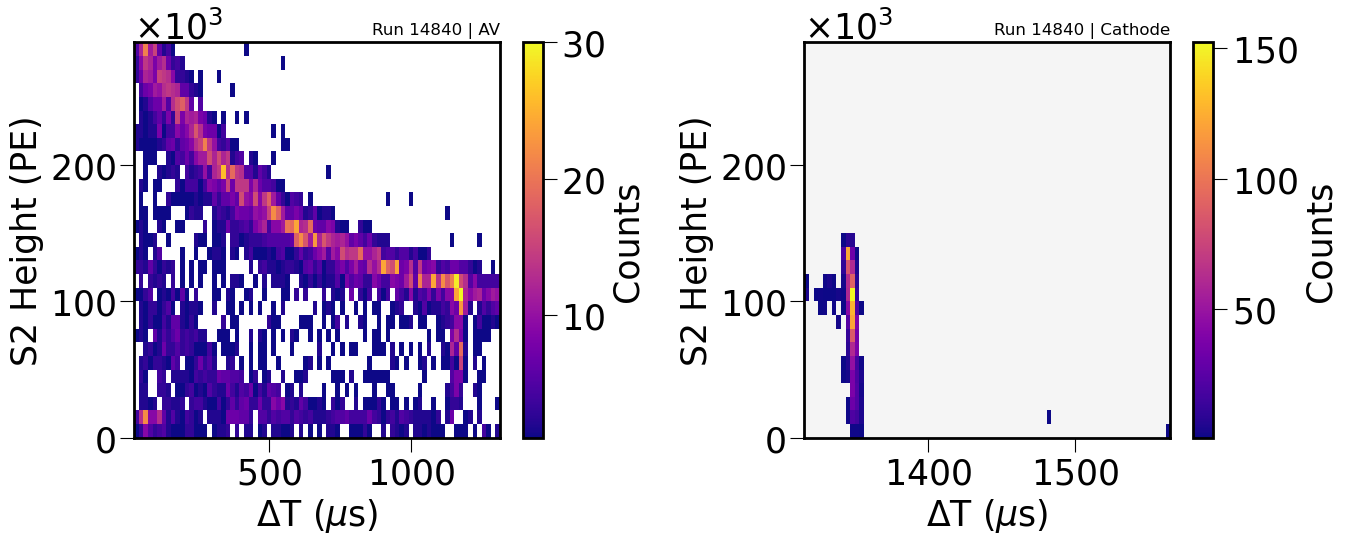

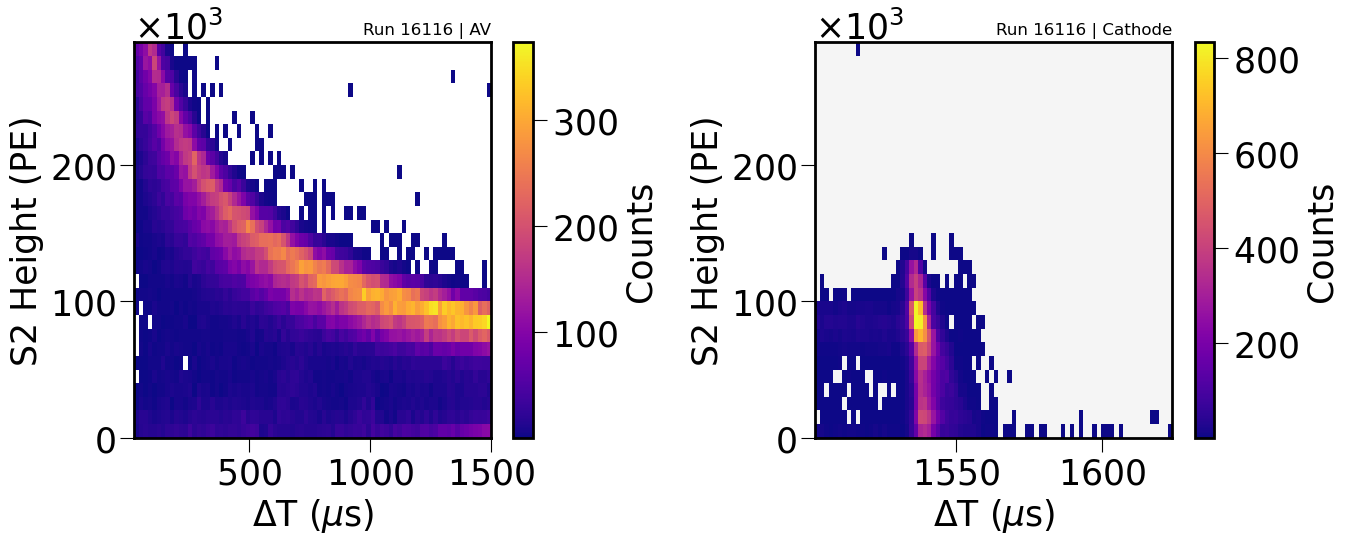

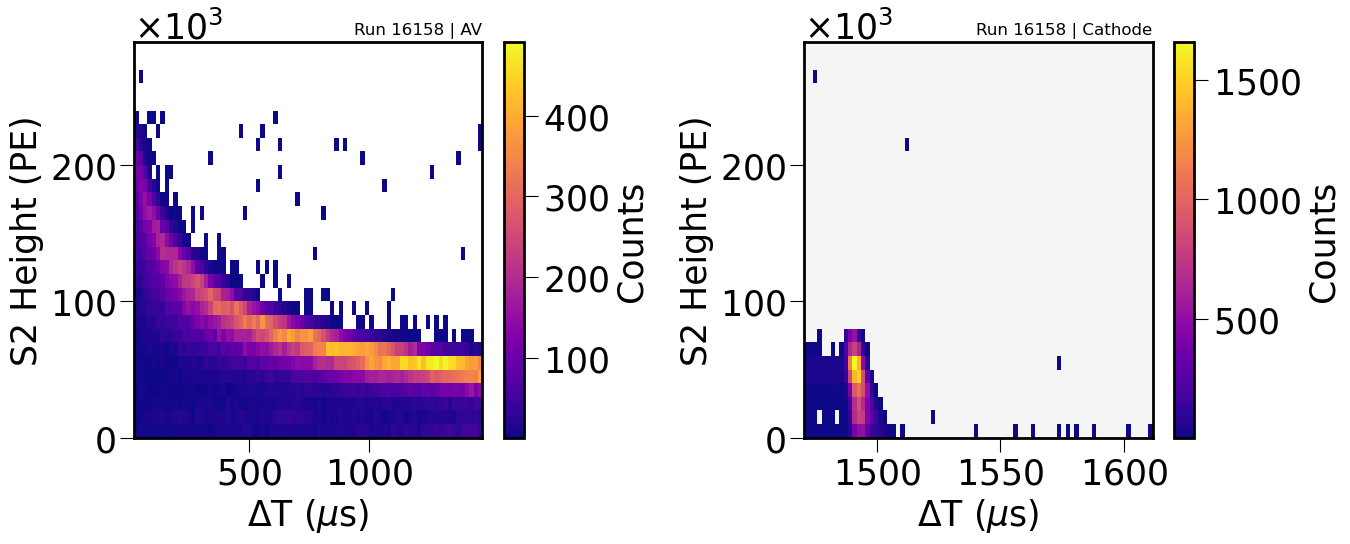

In [130]:
for key in SEL_DICT.keys():

    doro_df = SEL_DICT[key]['doro_df']

    fig = plt.figure(figsize=(14, 6))
    gs = GridSpec(1, 2, figure=fig)
    ax_left  = fig.add_subplot(gs[0, 0])
    ax_right = fig.add_subplot(gs[0, 1])

    for i, label in enumerate(['AV', 'Cathode']):

        if label == 'AV':
            mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask'])
            ax = ax_left
        else:
            mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['cath_mask'])
            ax = ax_right

        mask_df = doro_df[mask].copy()

        # Variables    
        DT = mask_df['DT']
        H2 = mask_df['S2h']

        # 2D Histogram
        s2h_dt_map, ex, ey = np.histogram2d(DT, H2, bins=[80, np.arange(0, 300e3, 10e3)])
        s2h_dt_map         = np.ma.masked_where(s2h_dt_map==0, s2h_dt_map)

        # Plot
        pcm = ax.pcolormesh(ex, ey, s2h_dt_map.T, cmap='plasma', shading='auto')
        plt.colorbar(pcm, ax=ax, label='Counts')
        ax.set_xlabel('$\Delta$T ($\mu$s)')
        ax.set_ylabel('S2 Height (PE)')
        ax.ticklabel_format(axis='y', style='sci', scilimits=(3, 3))
        ax.set_yticks(ey[::10])
        ax.set_title(f'Run {key} | {label}', loc='right', fontsize=12)

    plt.gca().set_facecolor("whitesmoke")
    plt.tight_layout()
    plt.show()

### $S1w$ vs $S2w$

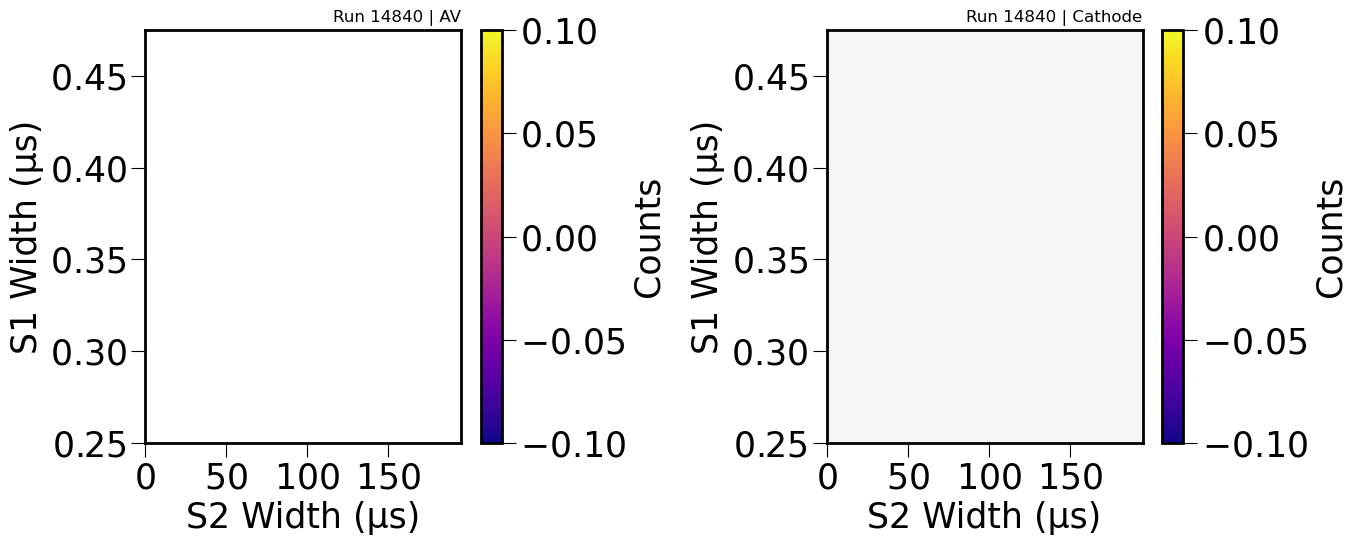

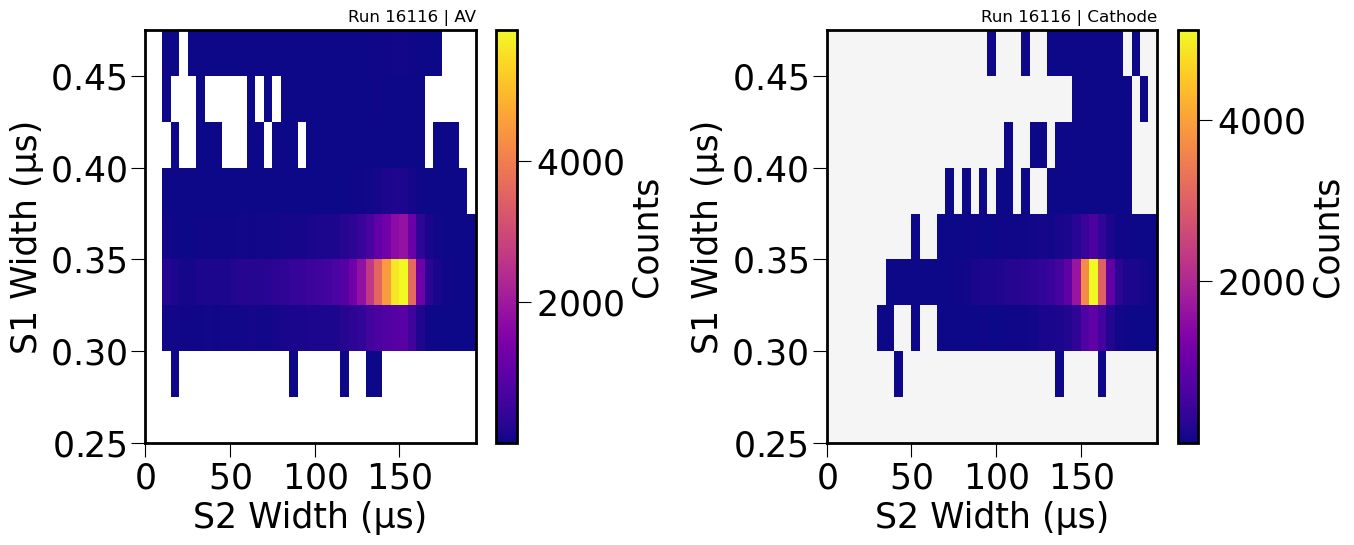

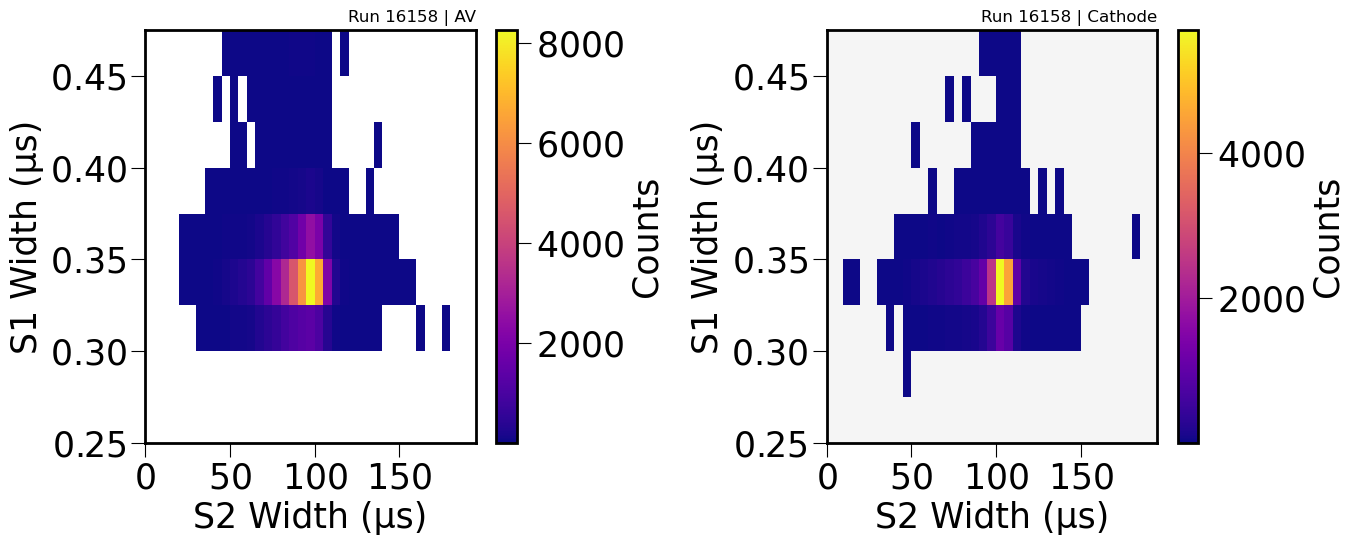

In [136]:
for key in SEL_DICT.keys():

    doro_df = SEL_DICT[key]['doro_df']

    fig = plt.figure(figsize=(14, 6))
    gs = GridSpec(1, 2, figure=fig)
    ax_left  = fig.add_subplot(gs[0, 0])
    ax_right = fig.add_subplot(gs[0, 1])

    for i, label in enumerate(['AV', 'Cathode']):

        if label == 'AV':
            mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['AV_Z_mask'])
            ax = ax_left
        else:
            mask = (EXTRA_INFO[key]['alpha_mask']) & (EXTRA_INFO[key]['cath_mask'])
            ax = ax_right

        mask_df = doro_df[mask].copy()

        # Variables    
        W1 = mask_df['S1w'] / 1e3
        W2 = mask_df['S2w']

        # 2D Histogram
        s1w_s2w_map, ex, ey = np.histogram2d(W2, W1, bins=[np.arange(0, 200, 5), np.arange(0.25, 0.5, 0.025)])
        s1w_s2w_map         = np.ma.masked_where(s1w_s2w_map==0, s1w_s2w_map)

        # Plot
        pcm = ax.pcolormesh(ex, ey, s1w_s2w_map.T, cmap='plasma', shading='auto')
        plt.colorbar(pcm, ax=ax, label='Counts')
        ax.set_xlabel('S2 Width (μs)')
        ax.set_ylabel('S1 Width (μs)')
        ax.set_xticks(ex[::10])
        ax.set_title(f'Run {key} | {label}', loc='right', fontsize=12)

    plt.gca().set_facecolor("whitesmoke")
    plt.tight_layout()
    plt.show()